In [ ]:
import pandas as pd

### Đọc dữ liệu từ file CSV

In [ ]:
df = pd.read_csv('/content/mobile_banking_may_log.csv')
display(df.head())

,Timestamp,User_ID,Device_OS,Feature_Triggered,Status,Transaction_Value_VND,Response_Time_ms
0,01-05-26 0:04,USR_501339,iOS,Transfer_Money,Success,15049485,299
1,01-05-26 0:16,USR_490355,iOS,Transfer_Money,Success,14462627,54
2,01-05-26 0:19,USR_385827,NaN,View_Balance,Success,8916143,307
3,01-05-26 0:19,USR_665709,iOS,View_Balance,Success,8860328,309
4,01-05-26 0:30,USR_443815,Android,Scan_QR_Payment,Success,2777812,325


### Kiểm tra thông tin cơ bản và chất lượng dữ liệu

In [ ]:
print('Thông tin tổng quan về DataFrame:')
df.info()

print('\nThống kê mô tả dữ liệu số:')
display(df.describe())

print('\nSố lượng giá trị thiếu trong mỗi cột:')
display(df.isnull().sum())

print('\nSố lượng hàng trùng lặp:')
print(df.duplicated().sum())

Thông tin tổng quan về DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   Timestamp              5000 non-null   object
 1   User_ID                5000 non-null   object
 2   Device_OS              4742 non-null   object
 3   Feature_Triggered      5000 non-null   object
 4   Status                 5000 non-null   object
 5   Transaction_Value_VND  5000 non-null   int64 
 6   Response_Time_ms       5000 non-null   int64 
dtypes: int64(2), object(5)
memory usage: 273.6+ KB

Thống kê mô tả dữ liệu số:


,Transaction_Value_VND,Response_Time_ms
count,5.000000e+03,5000.000000
mean,9.240320e+06,280.714200
std,6.862167e+06,790.789108
min,-1.000000e+00,50.000000
25%,3.492073e+06,139.000000
50%,9.135500e+06,227.000000
75%,1.471822e+07,314.000000
max,1.215647e+08,14782.000000



Số lượng giá trị thiếu trong mỗi cột:


,0
Timestamp,0
User_ID,0
Device_OS,258
Feature_Triggered,0
Status,0
Transaction_Value_VND,0
Response_Time_ms,0



Số lượng hàng trùng lặp:
0


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')

### Trực quan hóa các cột phân loại

/tmp/ipykernel_573/1208828967.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Device_OS', palette='viridis')


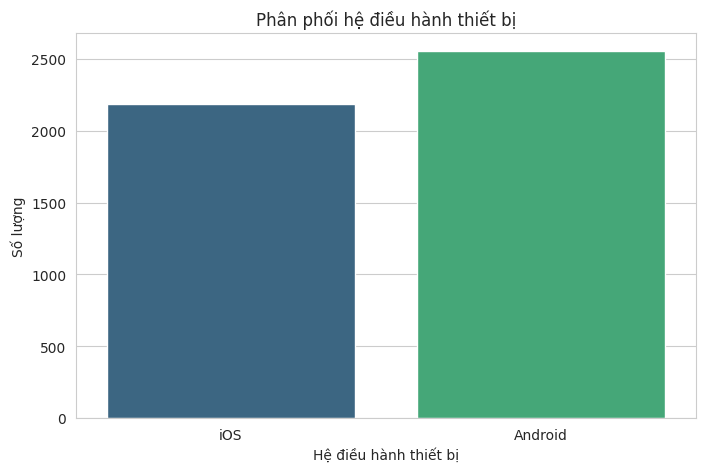

In [ ]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Device_OS', palette='viridis')
plt.title('Phân phối hệ điều hành thiết bị')
plt.xlabel('Hệ điều hành thiết bị')
plt.ylabel('Số lượng')
plt.show()

/tmp/ipykernel_573/2384191233.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Feature_Triggered', palette='magma')


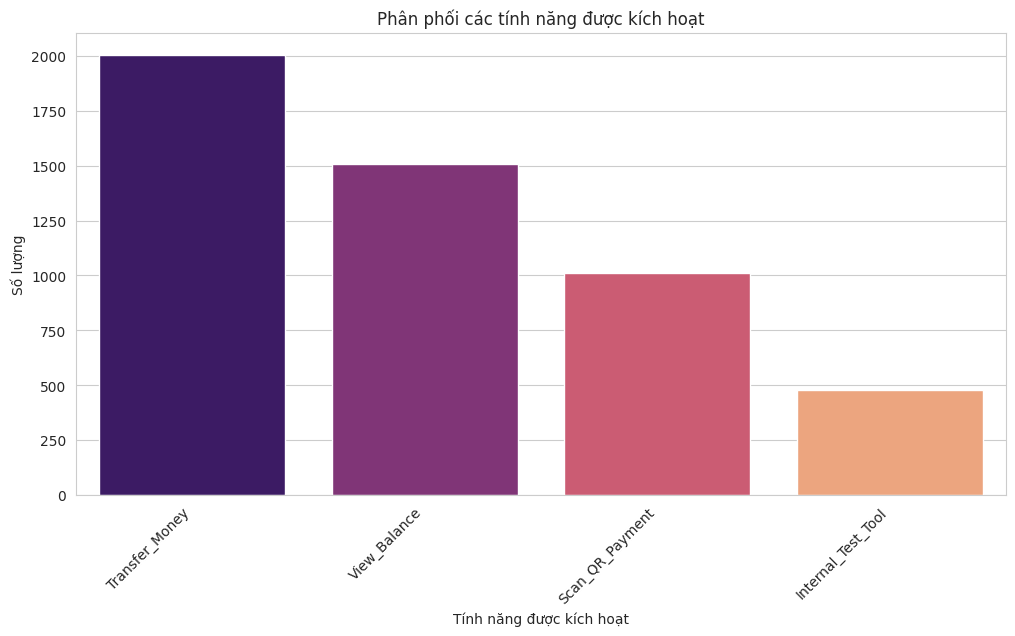

In [ ]:
plt.figure(figsize=(12, 6))
sns.countplot(data=df, x='Feature_Triggered', palette='magma')
plt.title('Phân phối các tính năng được kích hoạt')
plt.xlabel('Tính năng được kích hoạt')
plt.ylabel('Số lượng')
plt.xticks(rotation=45, ha='right')
plt.show()

/tmp/ipykernel_573/4246098840.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Status', palette='cividis')


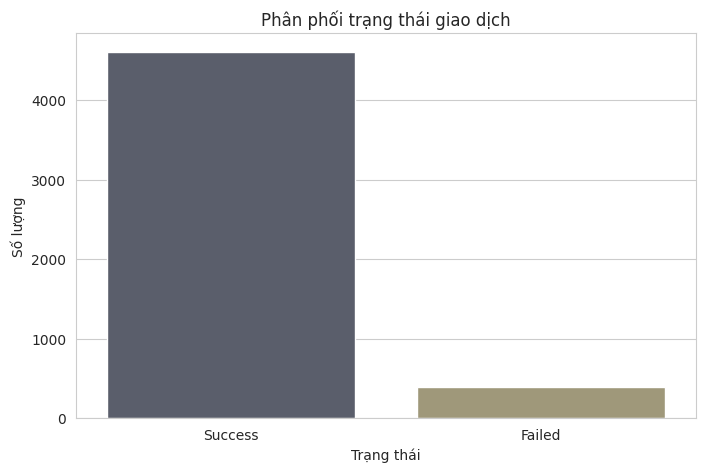

In [ ]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Status', palette='cividis')
plt.title('Phân phối trạng thái giao dịch')
plt.xlabel('Trạng thái')
plt.ylabel('Số lượng')
plt.show()

### Trực quan hóa các cột số

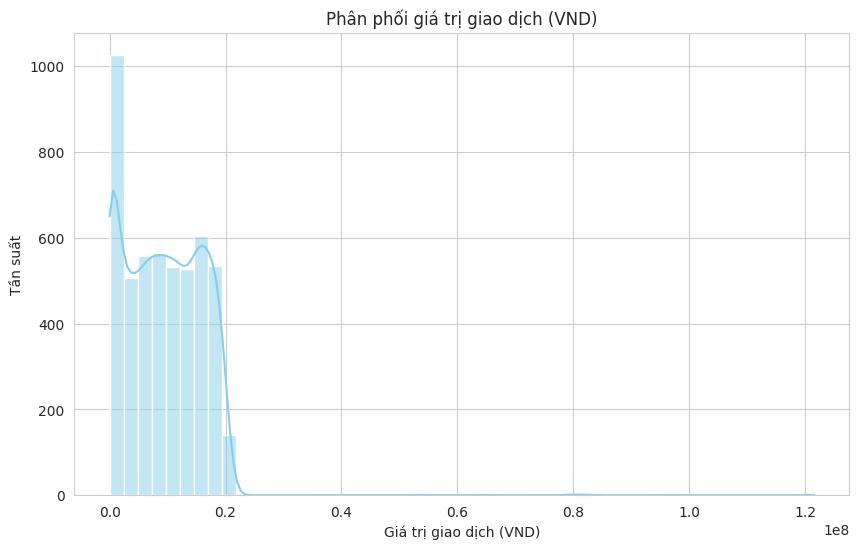

In [ ]:
plt.figure(figsize=(10, 6))
sns.histplot(df['Transaction_Value_VND'], bins=50, kde=True, color='skyblue')
plt.title('Phân phối giá trị giao dịch (VND)')
plt.xlabel('Giá trị giao dịch (VND)')
plt.ylabel('Tần suất')
plt.show()

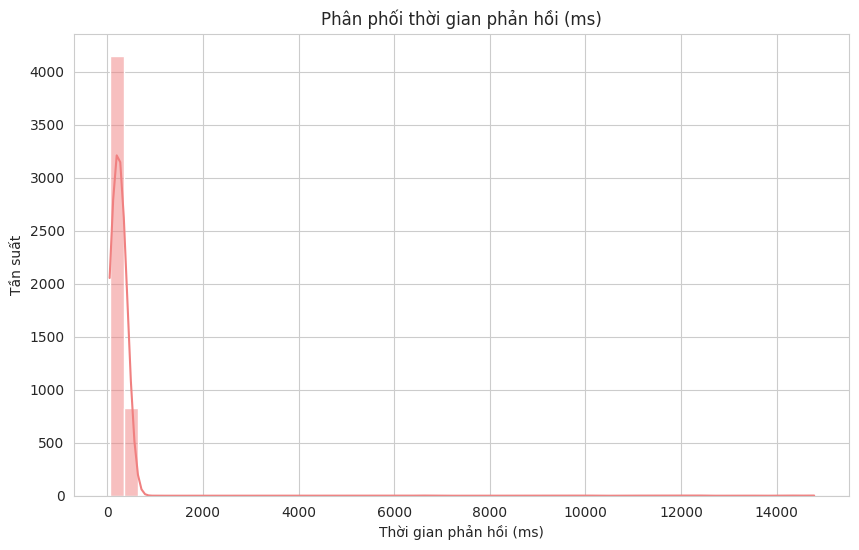

In [ ]:
plt.figure(figsize=(10, 6))
sns.histplot(df['Response_Time_ms'], bins=50, kde=True, color='lightcoral')
plt.title('Phân phối thời gian phản hồi (ms)')
plt.xlabel('Thời gian phản hồi (ms)')
plt.ylabel('Tần suất')
plt.show()

### Xử lý giá trị thiếu và bất thường

In [ ]:
import numpy as np

# Điền giá trị thiếu trong Device_OS bằng 'Unknown'
df['Device_OS'].fillna('Unknown', inplace=True)
print('Đã điền giá trị thiếu trong Device_OS bằng "Unknown"')

# Thay thế giá trị -1 trong Transaction_Value_VND bằng NaN
df['Transaction_Value_VND'].replace(-1, np.nan, inplace=True)
print('Đã thay thế giá trị -1 trong Transaction_Value_VND bằng NaN')

# Kiểm tra lại số lượng giá trị thiếu sau khi xử lý
print('\nSố lượng giá trị thiếu sau khi xử lý:')
display(df.isnull().sum())

Đã điền giá trị thiếu trong Device_OS bằng "Unknown"
Đã thay thế giá trị -1 trong Transaction_Value_VND bằng NaN

Số lượng giá trị thiếu sau khi xử lý:


/tmp/ipykernel_573/3437089575.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Device_OS'].fillna('Unknown', inplace=True)
/tmp/ipykernel_573/3437089575.py:8: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try usi

,0
Timestamp,0
User_ID,0
Device_OS,0
Feature_Triggered,0
Status,0
Transaction_Value_VND,355
Response_Time_ms,0


### Lưu bộ dữ liệu đã làm sạch

In [ ]:
# Chuyển đổi cột 'Timestamp' sang định dạng datetime
df['Timestamp'] = pd.to_datetime(df['Timestamp'], format='%y-%m-%d %H:%M')

# Lưu DataFrame đã làm sạch vào file CSV mới
output_file_path = '/content/mobile_banking_may_log_cleaned.csv'
df.to_csv(output_file_path, index=False)
print(f'Dữ liệu đã được lưu vào: {output_file_path}')

Dữ liệu đã được lưu vào: /content/mobile_banking_may_log_cleaned.csv


### Các insight tiềm năng từ dữ liệu đã làm sạch

In [ ]:
# Chuyển đổi 'Status' thành dạng số để tính toán tỷ lệ thành công
df['Is_Success'] = df['Status'].apply(lambda x: 1 if x == 'Success' else 0)

# Trích xuất giờ từ Timestamp
df['Hour'] = df['Timestamp'].dt.hour
display(df.head())

,Timestamp,User_ID,Device_OS,Feature_Triggered,Status,Transaction_Value_VND,Response_Time_ms,Is_Success,Hour
0,2001-05-26 00:04:00,USR_501339,iOS,Transfer_Money,Success,15049485.0,299,1,0
1,2001-05-26 00:16:00,USR_490355,iOS,Transfer_Money,Success,14462627.0,54,1,0
2,2001-05-26 00:19:00,USR_385827,Unknown,View_Balance,Success,8916143.0,307,1,0
3,2001-05-26 00:19:00,USR_665709,iOS,View_Balance,Success,8860328.0,309,1,0
4,2001-05-26 00:30:00,USR_443815,Android,Scan_QR_Payment,Success,2777812.0,325,1,0


#### Insight 1: Hiệu suất các tính năng

In [ ]:
feature_performance = df.groupby('Feature_Triggered').agg(
    Total_Transactions=('Timestamp', 'count'),
    Success_Rate=('Is_Success', 'mean'),
    Avg_Transaction_Value=('Transaction_Value_VND', 'median'), # Sử dụng median do có outliers
    Avg_Response_Time=('Response_Time_ms', 'mean')
).sort_values(by='Total_Transactions', ascending=False)

print("\nHiệu suất các tính năng:\n")
display(feature_performance)


Hiệu suất các tính năng:



,Total_Transactions,Success_Rate,Avg_Transaction_Value,Avg_Response_Time
Feature_Triggered,,,,
Transfer_Money,2004,0.996507,10098021.5,226.084331
View_Balance,1509,1.000000,9954633.0,223.701127
Scan_QR_Payment,1010,0.971287,10508430.0,499.683168
Internal_Test_Tool,477,0.255765,0.0,226.945493


#### Insight 2: Hành vi theo hệ điều hành

In [ ]:
os_performance = df.groupby('Device_OS').agg(
    Total_Users=('User_ID', 'nunique'), # Số lượng người dùng duy nhất
    Total_Transactions=('Timestamp', 'count'),
    Success_Rate=('Is_Success', 'mean'),
    Avg_Transaction_Value=('Transaction_Value_VND', 'median'),
    Avg_Response_Time=('Response_Time_ms', 'mean')
).sort_values(by='Total_Transactions', ascending=False)

print("\nHành vi theo hệ điều hành:\n")
display(os_performance)


Hành vi theo hệ điều hành:



,Total_Users,Total_Transactions,Success_Rate,Avg_Transaction_Value,Avg_Response_Time
Device_OS,,,,,
Android,2552,2553,0.915002,9975424.0,334.139052
iOS,2185,2189,0.929191,9707445.0,225.399726
Unknown,258,258,0.926357,10073808.0,221.372093


#### Insight 3: Mẫu hình hoạt động theo giờ


Mẫu hình hoạt động theo giờ:



,Total_Transactions,Success_Rate,Avg_Transaction_Value,Avg_Response_Time
Hour,,,,
0,194,0.932990,9668116.0,232.711340
1,210,0.952381,10028658.0,218.833333
2,200,0.930000,9751013.0,212.765000
3,209,0.899522,10188978.0,222.306220
4,207,0.937198,9060331.5,218.014493
5,196,0.938776,9641464.5,227.270408
6,202,0.915842,10622441.0,221.485149
7,207,0.927536,10221662.0,240.671498
8,219,0.908676,9760173.0,233.296804


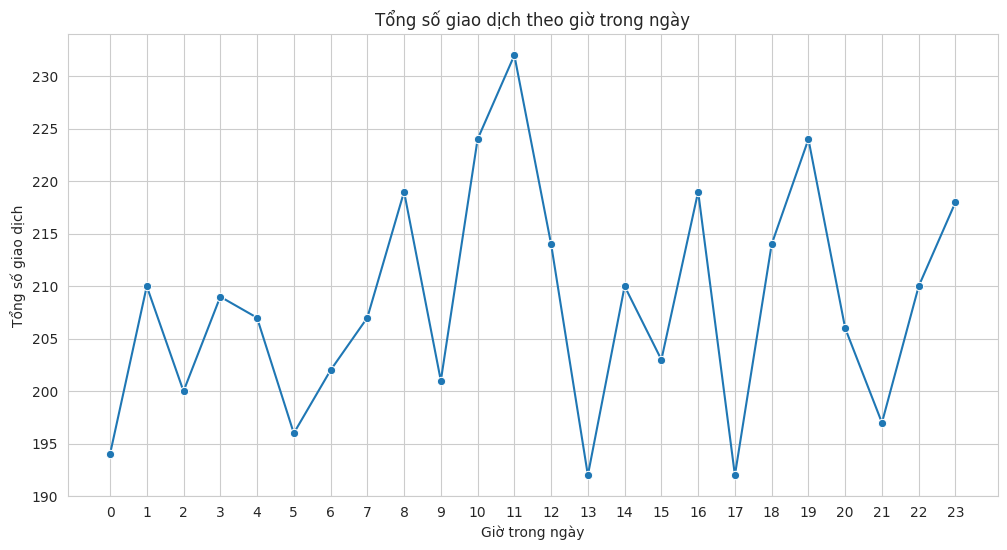

In [ ]:
hourly_activity = df.groupby('Hour').agg(
    Total_Transactions=('Timestamp', 'count'),
    Success_Rate=('Is_Success', 'mean'),
    Avg_Transaction_Value=('Transaction_Value_VND', 'median'),
    Avg_Response_Time=('Response_Time_ms', 'mean')
).sort_values(by='Hour')

print("\nMẫu hình hoạt động theo giờ:\n")
display(hourly_activity)

# Trực quan hóa hoạt động theo giờ
plt.figure(figsize=(12, 6))
sns.lineplot(data=hourly_activity, x='Hour', y='Total_Transactions', marker='o')
plt.title('Tổng số giao dịch theo giờ trong ngày')
plt.xlabel('Giờ trong ngày')
plt.ylabel('Tổng số giao dịch')
plt.xticks(range(24))
plt.grid(True)
plt.show()

### Insight bổ sung: Phân tích tỷ lệ lỗi

In [ ]:
# Tính toán tỷ lệ lỗi cho từng tính năng
feature_performance['Failure_Rate'] = 1 - feature_performance['Success_Rate']
print("\nTỷ lệ lỗi theo từng tính năng:\n")
display(feature_performance[['Total_Transactions', 'Success_Rate', 'Failure_Rate']].sort_values(by='Failure_Rate', ascending=False))

# Tính toán tỷ lệ lỗi cho từng hệ điều hành
os_performance['Failure_Rate'] = 1 - os_performance['Success_Rate']
print("\nTỷ lệ lỗi theo từng hệ điều hành:\n")
display(os_performance[['Total_Transactions', 'Success_Rate', 'Failure_Rate']].sort_values(by='Failure_Rate', ascending=False))


Tỷ lệ lỗi theo từng tính năng:



,Total_Transactions,Success_Rate,Failure_Rate
Feature_Triggered,,,
Internal_Test_Tool,477,0.255765,0.744235
Scan_QR_Payment,1010,0.971287,0.028713
Transfer_Money,2004,0.996507,0.003493
View_Balance,1509,1.000000,0.000000



Tỷ lệ lỗi theo từng hệ điều hành:



,Total_Transactions,Success_Rate,Failure_Rate
Device_OS,,,
Android,2553,0.915002,0.084998
Unknown,258,0.926357,0.073643
iOS,2189,0.929191,0.070809


#### Insight về tỷ lệ lỗi theo kết hợp Hệ điều hành và Tính năng

In [ ]:
failure_rate_by_os_feature = df.groupby(['Device_OS', 'Feature_Triggered']).agg(
    Total_Transactions=('Timestamp', 'count'),
    Success_Rate=('Is_Success', 'mean')
).reset_index()

failure_rate_by_os_feature['Failure_Rate'] = 1 - failure_rate_by_os_feature['Success_Rate']

print("\nTỷ lệ lỗi theo Hệ điều hành và Tính năng:\n")
display(failure_rate_by_os_feature.sort_values(by='Failure_Rate', ascending=False).head(10))


Tỷ lệ lỗi theo Hệ điều hành và Tính năng:



,Device_OS,Feature_Triggered,Total_Transactions,Success_Rate,Failure_Rate
4,Unknown,Internal_Test_Tool,25,0.240000,0.760000
0,Android,Internal_Test_Tool,250,0.256000,0.744000
8,iOS,Internal_Test_Tool,202,0.257426,0.742574
1,Android,Scan_QR_Payment,513,0.949318,0.050682
9,iOS,Scan_QR_Payment,431,0.993039,0.006961
2,Android,Transfer_Money,1008,0.995040,0.004960
10,iOS,Transfer_Money,907,0.997795,0.002205
3,Android,View_Balance,782,1.000000,0.000000
7,Unknown,View_Balance,78,1.000000,0.000000
6,Unknown,Transfer_Money,89,1.000000,0.000000


### Tìm một số insight có thể từ dữ liệu đã làm sạch